# Frequency, severity and pure premium models

This notebook aims to explore and build several GLM models on `mart_person_year` and explains each step for a reviewer. Several
candidate model structures predict the same quantity, the expected annual PMI-scope cost of a person-year at
2023 prices. They are compared on one yardstick before one is chosen. The notebook uses aggregated tables
only and shows no person-level rows.

**Source.** AHRQ, Medical Expenditure Panel Survey (MEPS), Household Component, full-year consolidated files
HC-243 (2022) and HC-251 (2023), with the inpatient, outpatient and office-based event files.

## Data and metrics

**Which rows.** Models are fitted on the 2022 `train` rows, and scored on the 2022 `test` rows. The test rows
are a household-grouped sample of 2022, so no household is on both sides. The 2023 rows are held back for
the out-of-time test and are not loaded here.

**What is predicted.** One row is one person-year. A prediction is the expected annual cost of that
person-year, with its exposure included, so a part-year person has a smaller expected cost. Costs are at 2023
prices. Models are fitted unweighted, because an insurer would fit on its own book.

**Factors.** The 18 rating factor candidates are typed as categories. The reference level of each is the level
with the most train exposure, and it can never be `not_applicable` or `unknown`. Age is shown in single years
here. Banding comes in the level grouping task.

**Metrics.** Every candidate is scored by the same package code.

- **Tweedie deviance** on annual cost, with power 1.5. The ranking is re-checked at 1.3 and 1.7.
- **Gini**, weighted by exposure, for how well the predictions rank the person-years.
- **Lift and double-lift** tables, which compare actual with expected cost by group.
- **A/E** (actual divided by expected) overall, by factor level and by predicted-cost decile. A decile is a
  tenth of the exposure, ordered by predicted cost per exposure year, so a part-year person is placed by their
  annual rate.

In [1]:
import pandas as pd

from health_pricing.models import frame, metrics

pd.options.display.float_format = "{:,.3f}".format
frames = frame.load_frames()
frame.frame_summary(frames)

,split,person_years,exposure,claimants,claimant_rate,zero_cost_claimants,claims,cost,mean_cost_per_claimant
0,train,17596,"17,440.750",7229,0.411,34,53322,"38,080,040.270","5,267.677"
1,test,4151,"4,100.333",1731,0.417,6,12463,"9,748,983.247","5,631.995"


About 41 to 42 percent of person-years have at least one PMI-scope claim in both splits. Mean cost per claimant is
higher in test than in train, which is the first sign of how much a skewed cost varies between samples.
A few claimants have a claim of zero cost, counted in the `zero_cost_claimants` column. They count as claimants, and the severity
models will need to treat them explicitly.

### Reference levels

Age has the most exposure at 85 only because single years are not yet banded, so its reference level is
temporary. The reference levels of the other factors are the largest groups, as intended.

In [2]:
frame.reference_table(frames)

,factor,reference_level,exposure_share
0,age,85,0.022
1,region,3,0.384
2,inscov,1,0.592
3,rthlth,2,0.325
4,mnhlth,2,0.311
5,OFTSMK53,3,0.702
6,PHYEXE53,1,0.400
7,HIBPDX,0,0.500
8,CHDDX,0,0.756
9,ANGIDX,0,0.787


### Baseline

The baseline predicts the same cost per exposure year for everyone, the train mean. Every candidate has to beat
it. Its Gini is 0 by construction, because it does not rank anyone, and its A/E on train is 1.

In [3]:
metrics.baseline_scores(frames.train, frames.test)

,split,tweedie_deviance,mean_tweedie_deviance,gini,a_e
0,train,"3,694,004.075",209.934,0.000,1.000
1,test,"928,363.961",223.648,0.000,1.089


In [4]:
baseline = metrics.baseline_predictions(frames.train, frames.test)
pd.DataFrame(metrics.deviance_by_power(frames.test["cost"], baseline), index=["Test deviance"])

,1.300,1.500,1.700
Test deviance,"4,118,785.057","928,363.961","252,758.818"


The baseline's test A/E is above 1, so test cost per exposure year is higher than train. Part of this is
sampling variation in a skewed cost. Every candidate's test A/E should be read against this starting gap.
Deviances at different powers are on different scales, so they are only compared between candidates at the
same power. The power check asks whether the ranking of candidates changes.

## Benefit types

The stacked candidate (c) models the two benefit types separately. `mart_person_year_benefit` has two rows for
every person-year, with zeros where there is nothing to count. Event counts and costs add up to the claim
columns of the main modelling table.

- **Inpatient and day-case.** Every in-scope inpatient stay, and every in-scope outpatient or office-based visit
  where a surgical procedure was performed on the visit (`SURGPROC` = 1).
- **Outpatient.** All other in-scope visits. Visits where the procedure flag is inapplicable, refused or
  unknown are counted here.

The tables use 2023 prices and cover the modelling population.

In [5]:
from health_pricing import eda
from health_pricing.models import benefit

con = eda.connect()
benefit.benefit_summary(con)

,year,benefit_type,person_years,claimants,events,cost_2023_prices,events_share,cost_2023_prices_share
0,2022,inpatient_daycase,21747,"2,464.000","4,863.000","22,715,964.261",0.074,0.475
1,2022,outpatient,21747,"8,468.000","60,922.000","25,113,059.256",0.926,0.525
2,2023,inpatient_daycase,18463,"2,228.000","4,548.000","25,137,095.400",0.074,0.538
3,2023,outpatient,18463,"7,381.000","56,633.000","21,567,598.100",0.926,0.462


### What the procedure flag moves

This table covers every in-scope event in the event files, including people outside the modelling population,
at the prices of each survey year. The `all in-scope events` rows include the inpatient stays, which are never
moved. The flag moves a small share of events but a large share of cost, mainly in hospital outpatient visits.
The flag is a yes or no for the whole visit, so a minor procedure in a doctor's office counts as day-case.

In [6]:
shift = benefit.surgproc_shift(con)
con.close()
shift

,year,event_type,events,moved_events,cost,moved_cost,moved_events_share,moved_cost_share
0,2022,office_based,52602,2692,"19,541,406.280","2,808,890.470",0.051,0.144
1,2022,outpatient,13084,1506,"14,573,992.140","6,525,104.460",0.115,0.448
2,2022,all in-scope events,66406,4198,"47,120,394.730","9,333,994.930",0.063,0.198
3,2023,office_based,49654,2388,"17,166,857.780","2,122,309.290",0.048,0.124
4,2023,outpatient,11378,1459,"13,087,546.120","6,369,904.530",0.128,0.487
5,2023,all in-scope events,61792,3847,"47,159,982.900","8,492,213.820",0.062,0.180


## Leakage check on the unknown level

Adults who were never asked a question have the level `unknown`. For example, people who left the survey before
round 5/3, or who died before the priority-conditions section, are not asked the smoking, exercise or condition
questions. If `unknown` is really a marker for leaving or dying, it would predict cost for the wrong reason and
could not be used when pricing a policy. This section tests that on the 13 candidate factors that have an
`unknown` level. It uses adults in the 2022 train split only.

For each variable, adults at `unknown` are compared with adults who gave an answer. People who refused or did not
know are in neither group.

In [7]:
import matplotlib.pyplot as plt

from health_pricing.models import leakage

adults = leakage.load_leakage_frame()
comparison = leakage.unknown_level_table(adults)
comparison

,variable,group,person_years,mean_age,share_under_25,share_left_survey_early,share_exposure_under_1,mean_exposure,claimant_rate,mean_cost_per_claimant,cost_per_exposure_year
0,OFTSMK53,unknown,186,71.430,0.027,0.747,0.892,0.509,0.398,"27,712.301","21,643.380"
1,OFTSMK53,answered,13895,51.746,0.082,0.000,0.001,1.000,0.468,"5,293.445","2,476.125"
2,PHYEXE53,unknown,186,71.430,0.027,0.747,0.892,0.509,0.398,"27,712.301","21,643.380"
3,PHYEXE53,answered,13859,51.753,0.082,0.000,0.001,1.000,0.469,"5,290.742","2,479.764"
4,HIBPDX,unknown,113,29.062,0.805,0.177,0.212,0.829,0.230,"1,730.804",480.437
5,HIBPDX,answered,14080,52.146,0.077,0.008,0.011,0.994,0.467,"5,556.539","2,608.726"
6,CHDDX,unknown,113,29.062,0.805,0.177,0.212,0.829,0.230,"1,730.804",480.437
7,CHDDX,answered,14083,52.145,0.077,0.008,0.011,0.994,0.467,"5,550.613","2,604.990"
8,ANGIDX,unknown,113,29.062,0.805,0.177,0.212,0.829,0.230,"1,730.804",480.437
9,ANGIDX,answered,14084,52.143,0.077,0.008,0.011,0.994,0.467,"5,551.442","2,604.796"


The smoking and exercise questions have the same 186 adults at `unknown`. The nine adult-only condition flags have the
same 113, and the two flags asked at any age have the same 24. So the 13 rows above are only three different
groups of people.

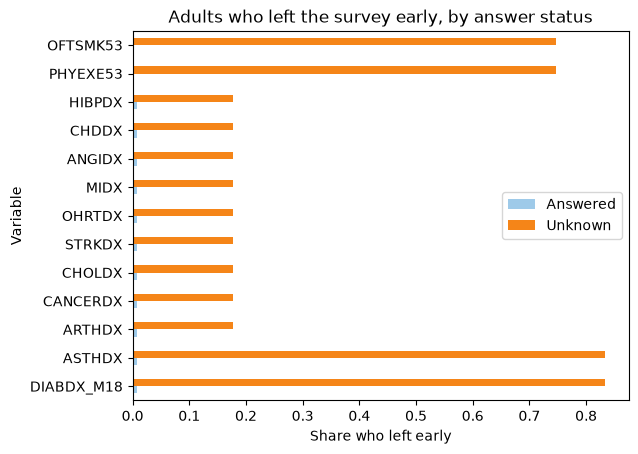

In [8]:
wide = comparison.pivot(index="variable", columns="group", values="share_left_survey_early")
ax = wide.loc[leakage.UNKNOWN_VARIABLES[::-1]].plot.barh(
    color={"answered": "#9ecae9", "unknown": "#f58518"}
)
ax.set_title("Adults who left the survey early, by answer status")
ax.set_xlabel("Share who left early")
ax.set_ylabel("Variable")
ax.legend(["Answered", "Unknown"], title=None)
plt.show()

### The other direction

Of the adults who left the survey early, what share are `unknown`? If it is close to all of them, `unknown` is a
leaver marker.

In [9]:
leavers = leakage.unknown_by_leaver_table(adults)
leavers

,variable,leavers,leavers_unknown_share,stayers_unknown_share
0,OFTSMK53,139,1.000,0.003
1,PHYEXE53,139,1.000,0.003
2,HIBPDX,137,0.146,0.007
3,CHDDX,137,0.146,0.007
4,ANGIDX,137,0.146,0.007
5,MIDX,137,0.146,0.007
6,OHRTDX,137,0.146,0.007
7,STRKDX,137,0.146,0.007
8,CHOLDX,137,0.146,0.007
9,CANCERDX,137,0.146,0.007


### What merging unknown into the reference level would do

The reference level is the answered level with the most exposure. If `unknown` were merged into it, the reference
cost per exposure year would move as shown. A large move means the `unknown` person-years would distort the
reference and so every relativity of that factor.

In [10]:
leakage.merge_effect_table(adults)

,variable,reference_level,unknown_share_of_reference_exposure,reference_cost_per_exposure_year,cost_after_merge,change_after_merge
0,OFTSMK53,3,0.008,"2,537.876","2,684.859",0.058
1,PHYEXE53,1,0.014,"2,152.138","2,414.039",0.122
2,HIBPDX,0,0.011,"1,700.895","1,687.882",-0.008
3,CHDDX,0,0.007,"2,294.469","2,281.653",-0.006
4,ANGIDX,0,0.007,"2,561.540","2,547.415",-0.006
5,MIDX,0,0.007,"2,454.519","2,440.842",-0.006
6,OHRTDX,0,0.008,"2,244.590","2,231.249",-0.006
7,STRKDX,0,0.007,"2,464.154","2,450.315",-0.006
8,CHOLDX,0,0.010,"1,828.378","1,814.463",-0.008
9,CANCERDX,0,0.008,"2,019.838","2,008.057",-0.006


### Recommendation for each variable

The decision is taken in the level grouping task. This is the evidence-based recommendation to it. No variable
should be dropped.

| Variables | What the evidence shows | Recommendation |
|---|---|---|
| `OFTSMK53`, `PHYEXE53` | 186 adult person-years. 75 percent left the survey early, 89 percent are part-year, the mean age is 71, and the cost per exposure year is about 21,600 dollars against about 2,500 for adults who answered. Every adult who left early is `unknown`. | **Keep the level in the fit only**, as a control that absorbs the leaver effect. Merging it would raise the reference cost by 5.8 percent for smoking and 12.2 percent for exercise. At rating, treat everyone as the reference level, and never offer `unknown` as a rating level. |
| The nine adult-only condition flags | 113 adult person-years, about 79 percent aged exactly 18, with a low cost per exposure year of about 480 dollars. Most are people who turned 18 during the year. A minority (18 percent) left early, and only 15 percent of leavers are `unknown`. | **Merge into the reference level** (`0`). The reference cost moves by less than 1 percent. |
| `ASTHDX`, `DIABDX_M18` | 24 adult person-years with about 5 years of exposure between them. Most (83 percent) left early. | **Merge into the reference level** (`0`). The reference cost moves by less than 0.1 percent. |

## Rating-factor levels (decision gate 6)

Before any model is fitted, the levels of each rating factor candidate have to be agreed. Levels with few claimants
give unstable relativities, so they are merged. This section shows the evidence and the grouping. The user
approved it at decision gate 6 on 2 November 2026, with the two changes noted below.

All counts are for the 2022 train split. A **claimant** is a person-year with at least one claim. A level is
**thin** if it has fewer than 30 claimants. The `unknown` level is explained in the leakage check above, and
`not_applicable` is a child on an adult-only question.

In [11]:
from health_pricing.models import frame, levels

frames = frame.load_frames()
evidence = levels.level_evidence(frames.train)
evidence[evidence["factor"] != "age"]

,factor,level,person_years,exposure,claimants,claims,claimant_rate,cost_per_exposure_year,thin
86,region,1,2795,"2,771.250",1319,11562,0.472,"2,636.650",False
87,region,2,3535,"3,504.917",1530,10605,0.433,"2,294.140",False
88,region,3,6764,"6,704.333",2507,17826,0.371,"2,015.656",False
89,region,4,4502,"4,460.250",1873,13329,0.416,"2,066.885",False
90,inscov,1,10382,"10,321.333",4504,32037,0.434,"2,242.807",False
...,...,...,...,...,...,...,...,...,...
164,ASTHDX,unknown,43,8.167,5,7,0.116,"11,458.065",True
165,DIABDX_M18,0,15520,"15,423.500",5966,42762,0.384,"1,902.738",False
166,DIABDX_M18,1,2024,"2,002.167",1257,10548,0.621,"4,314.496",False
167,DIABDX_M18,missing,9,6.917,1,5,0.111,180.120,True


### Thin levels

Every thin level below is a placeholder (`missing` or `unknown`) and not a real answer. No real answer level of any
factor is thin. Single years of age are left out here. Some are thin, and they are banded in the next section.

In [12]:
thin = evidence[evidence["thin"] & (evidence["factor"] != "age")]
thin

,factor,level,person_years,exposure,claimants,claims,claimant_rate,cost_per_exposure_year,thin
98,rthlth,missing,49,7.833,7,10,0.143,"6,740.051",True
104,mnhlth,missing,50,8.417,7,10,0.140,"6,272.918",True
118,HIBPDX,missing,17,15.917,0,0,0.000,0.000,True
120,HIBPDX,unknown,113,93.667,26,160,0.230,480.437,True
123,CHDDX,missing,14,12.917,1,5,0.071,"3,445.576",True
125,CHDDX,unknown,113,93.667,26,160,0.230,480.437,True
128,ANGIDX,missing,13,11.917,2,7,0.154,"3,743.665",True
130,ANGIDX,unknown,113,93.667,26,160,0.230,480.437,True
133,MIDX,missing,8,6.917,0,0,0.000,0.000,True
135,MIDX,unknown,113,93.667,26,160,0.230,480.437,True


### Age bands

Claimant rate rises steadily from the late twenties to the late seventies. It dips after 80, where age is capped at
85 and the top group mixes everyone aged 80 and over. Two proposals are compared. **Five-year bands** have 16 bands
and the fewest claimants in any band is 108. **Ten-year bands** have 10 bands and the fewest is also 108. The ten-year
bands hide some of the slope inside a band, for example the claimant rate is 49 percent at ages 55 to 59 and
56 percent at ages 60 to 64, and a ten-year band merges them.

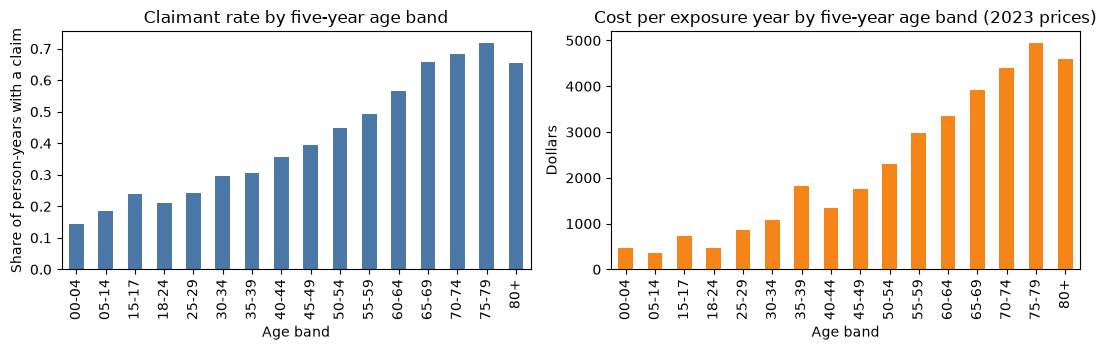

,band,person_years,exposure,claimants,claimant_rate,cost_per_exposure_year,thin
0,00-04,749,693.250,108,0.144,463.111,False
1,05-14,2004,"2,002.417",369,0.184,362.918,False
2,15-17,634,634.000,152,0.240,723.324,False
3,18-24,1173,"1,168.917",247,0.211,466.591,False
4,25-29,947,944.667,229,0.242,868.374,False
5,30-34,1021,"1,019.583",303,0.297,"1,075.215",False
6,35-39,1119,"1,115.500",341,0.305,"1,813.724",False
7,40-44,1048,"1,046.167",372,0.355,"1,346.983",False
8,45-49,996,994.333,392,0.394,"1,753.727",False
9,50-54,1128,"1,126.833",505,0.448,"2,297.019",False


In [13]:
import matplotlib.pyplot as plt

five = levels.age_band_table(frames.train, levels.AGE_BANDS["five_year"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
five.plot.bar(x="band", y="claimant_rate", ax=axes[0], legend=False, color="#4c78a8")
axes[0].set_title("Claimant rate by five-year age band")
axes[0].set_xlabel("Age band")
axes[0].set_ylabel("Share of person-years with a claim")
five.plot.bar(x="band", y="cost_per_exposure_year", ax=axes[1], legend=False, color="#f58518")
axes[1].set_title("Cost per exposure year by five-year age band (2023 prices)")
axes[1].set_xlabel("Age band")
axes[1].set_ylabel("Dollars")
plt.tight_layout()
plt.show()
five

In [14]:
levels.age_band_table(frames.train, levels.AGE_BANDS["ten_year"])

,band,person_years,exposure,claimants,claimant_rate,cost_per_exposure_year,thin
0,00-04,749,693.250,108,0.144,463.111,False
1,05-14,2004,"2,002.417",369,0.184,362.918,False
2,15-17,634,634.000,152,0.240,723.324,False
3,18-24,1173,"1,168.917",247,0.211,466.591,False
4,25-34,1968,"1,964.250",532,0.270,975.739,False
5,35-44,2167,"2,161.667",713,0.329,"1,587.839",False
6,45-54,2124,"2,121.167",897,0.422,"2,042.342",False
7,55-64,2512,"2,503.583",1332,0.530,"3,163.104",False
8,65-74,2486,"2,468.250",1663,0.669,"4,141.346",False
9,75+,1779,"1,723.250",1216,0.684,"4,762.043",False


### Rules (approved at gate 6)

| Case | Rule | Why |
|---|---|---|
| Age | Five-year bands as above, with 0 to 4, 5 to 14, 15 to 17 and 18 to 24 for the young and 80 and over as the top band | The claimant rate keeps rising from age 25 to 79, by up to 9 points per five years. Each band has at least 100 claimants |
| `not_applicable` (a child on an adult-only question) | Merge into the reference level | A child cannot be a smoker or have an adult condition flag. The age bands carry the effect of being a child. A separate level would only repeat the child age bands |
| `unknown` on `OFTSMK53` and `PHYEXE53` | Keep as a level in the fit only, and price it at the reference | The leakage check shows it marks adults who left the survey early. Merging it would distort the reference cost by 6 and 12 percent |
| `unknown` on the 11 condition flags | Merge into the reference level | The leakage check shows a small, mostly young group with low cost. Merging moves the reference cost by under 1 percent. The test applied at the gate is that `unknown` is kept as a control wherever merging would move the reference cost by more than 2 percent, and the table below shows it is met by `OFTSMK53` and `PHYEXE53` only |
| Null (refused, don't know, cannot be computed, or no valid round for health status) | Merge into the reference level | At most 165 person-years for any factor, so the effect on the reference level is small |
| Any other level with fewer than 30 claimants | Merge into the reference level | No real answer level is thin today, so this rule changes nothing now. It is a safeguard for later refits |
| Reference level | The real answer with the most exposure, never a placeholder | The usual convention. It can be rebased to another level when relativities are presented, without changing the model. For age, relativities are presented against the adult band with the most exposure, and the technical reference stays 5 to 14 |

The next table shows the gate 6 test for each variable with an `unknown` level. It is the change in the reference
cost per exposure year if `unknown` were merged into the reference level, using adults in the train split. Only the
smoking and exercise questions are above 2 percent, so only they keep `unknown` as a control.

In [15]:
rule = levels.unknown_rule_table()
rule[
    [
        "variable",
        "reference_level",
        "unknown_share_of_reference_exposure",
        "change_after_merge",
        "exceeds_limit",
        "kept_as_control",
    ]
]

,variable,reference_level,unknown_share_of_reference_exposure,change_after_merge,exceeds_limit,kept_as_control
0,OFTSMK53,3,0.008,0.058,True,True
1,PHYEXE53,1,0.014,0.122,True,True
2,HIBPDX,0,0.011,-0.008,False,False
3,CHDDX,0,0.007,-0.006,False,False
4,ANGIDX,0,0.007,-0.006,False,False
5,MIDX,0,0.007,-0.006,False,False
6,OHRTDX,0,0.008,-0.006,False,False
7,STRKDX,0,0.007,-0.006,False,False
8,CHOLDX,0,0.010,-0.008,False,False
9,CANCERDX,0,0.008,-0.006,False,False


In [16]:
grouping = levels.decided_grouping(frames)
summary = levels.grouping_summary(frames, grouping)
summary[summary["factor"] != "age"]

,factor,group,reference,levels_merged,person_years,exposure,claimants
16,region,1,False,1,2795,"2,771.250",1319
17,region,2,False,2,3535,"3,504.917",1530
18,region,3,True,3,6764,"6,704.333",2507
19,region,4,False,4,4502,"4,460.250",1873
20,inscov,1,True,1,10382,"10,321.333",4504
21,inscov,2,False,2,6040,"5,962.833",2630
22,inscov,3,False,3,1174,"1,156.583",95
23,rthlth,1,False,1,4459,"4,413.667",1115
24,rthlth,2,True,"2, missing",5745,"5,680.750",2414
25,rthlth,3,False,3,5167,"5,146.250",2301


In [17]:
technical = grouping.reference["age"]
presentation = levels.presentation_age_reference(frames, grouping)
print(
    f"Technical age reference: {technical}. Age relativities are presented against: {presentation}."
)
saved = levels.save_grouping(grouping)
print(f"Saved the level map ({len(grouping.table())} rows) to outputs/m3_draft/{saved.name}")

Technical age reference: 05-14. Age relativities are presented against: 65-69.
Saved the level map (169 rows) to outputs/m3_draft/level_grouping.csv


### Insurance coverage: two options for gate 7

`inscov` is any private (1), public only (2) or uninsured (3). The uninsured claimant rate reflects access to care in
the US and not risk. Gate 7 decides whether `inscov` is a permitted rating factor and how to treat it. Two options are
compared on the figures below. **(a)** restricts the modelling population to privately insured persons. **(b)**
keeps everyone, and fits `inscov` as a control that is priced at the private level.

In [18]:
levels.inscov_table(frames.train)

,level,person_years,exposure,claimants,mean_age,share_over_65,share_under_18,claimant_rate,cost_per_exposure_year,person_years_share,exposure_share,claimants_share,cost_share
0,1,10382,"10,321.333",4504,42.220,0.176,0.176,0.434,"2,242.807",0.590,0.592,0.623,0.608
1,2,6040,"5,962.833",2630,47.144,0.400,0.245,0.435,"2,454.049",0.343,0.342,0.364,0.384
2,3,1174,"1,156.583",95,39.386,0.019,0.063,0.081,257.824,0.067,0.066,0.013,0.008


In [19]:
levels.inscov_table(frames.test)

,level,person_years,exposure,claimants,mean_age,share_over_65,share_under_18,claimant_rate,cost_per_exposure_year,person_years_share,exposure_share,claimants_share,cost_share
0,1,2341,"2,322.583",1065,42.983,0.180,0.164,0.455,"2,579.539",0.564,0.566,0.615,0.615
1,2,1514,"1,486.667",643,47.721,0.416,0.246,0.425,"2,464.284",0.365,0.363,0.371,0.376
2,3,296,291.083,23,38.078,0.020,0.105,0.078,323.686,0.071,0.071,0.013,0.010


## Large claims (decision gate 5)

A few very large person-years carry a large share of cost and make mean severity unstable. A model fitted on raw cost
would chase them. The usual treatment is to **cap** annual cost per person-year at a threshold, model the capped cost,
and add the excess back as a **loading** on the final price. This section shows the evidence for the threshold and for
the loading. The user approved it at decision gate 5 on 2 November 2026, with the additions noted at the end of the section.

The cap applies to annual cost per person-year (the sum of every in-scope claim of the person in the year), at 2023
prices. `mart_person_year` does not change, because the capped cost is computed in the package when a model is fitted.
All figures use the 2022 train claimants (7,229 person-years with a claim) unless a table says it is test.

In [20]:
from health_pricing.models import large_claims

train_claimants = frames.train[frames.train["claimant"] == 1]
test_claimants = frames.test[frames.test["claimant"] == 1]
large_claims.percentile_table(train_claimants["cost"])

,percentile,cost_per_claimant
0,P50,"1,032.336"
1,P60,"1,687.425"
2,P70,"2,821.734"
3,P75,"3,793.179"
4,P80,"5,411.985"
5,P90,"13,033.787"
6,P95,"23,034.955"
7,P97.5,"37,321.716"
8,P99,"62,975.621"
9,P99.5,"92,708.844"


### Candidate caps

Six caps are compared. Three are percentiles of train cost per claimant (99, 99.5 and 99.9) and three are fixed dollar
amounts (50,000, 100,000 and 250,000 at 2023 prices). For each cap the table shows the claimants above it, the share
of cost above it (the excess), and the effect on mean severity. The share of cost above the cap equals the fall in
mean severity, because severity is total cost over claimants.

In [21]:
caps = large_claims.resolve_caps(train_claimants["cost"])
large_claims.cap_comparison(train_claimants["cost"], caps)

,cap,cap_amount,claimants_above,share_of_claimants_above,share_of_cost_above_cap,mean_severity,mean_severity_capped,change_in_mean_severity
0,"$50,000","50,000.000",109,0.015,0.139,"5,267.677","4,535.686",-0.139
1,P99,"62,975.621",73,0.010,0.109,"5,267.677","4,694.759",-0.109
2,P99.5,"92,708.844",37,0.005,0.067,"5,267.677","4,912.644",-0.067
3,"$100,000","100,000.000",32,0.004,0.061,"5,267.677","4,947.494",-0.061
4,P99.9,"207,458.023",8,0.001,0.020,"5,267.677","5,161.975",-0.020
5,"$250,000","250,000.000",4,0.001,0.013,"5,267.677","5,199.921",-0.013


### Does the tail look the same on test?

A cap is set on train, so it should behave similarly on rows it has not seen. The test split has 1,731 claimants and
very few above any cap, so its shares are noisy. The table applies the same train caps to both splits. The test tail
is heavier than the train tail at every cap, for example 10.8 percent of test cost is above 100,000 against 6.1 percent
of train cost, from 11 claimants against 32. This is a reminder of how few claimants drive the tail.

In [22]:
stability = large_claims.stability_table(train_claimants["cost"], test_claimants["cost"], caps)
stability

,cap,cap_amount,train_claimants_above,train_share_of_cost_above_cap,test_claimants_above,test_share_of_cost_above_cap
0,"$50,000","50,000.000",109,0.139,29,0.202
1,P99,"62,975.621",73,0.109,26,0.166
2,P99.5,"92,708.844",37,0.067,12,0.116
3,"$100,000","100,000.000",32,0.061,11,0.108
4,P99.9,"207,458.023",8,0.020,3,0.048
5,"$250,000","250,000.000",4,0.013,2,0.037


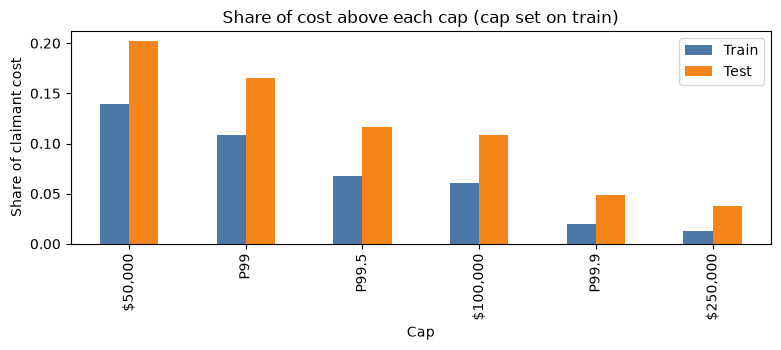

In [23]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.6))
stability.plot.bar(
    x="cap",
    y=["train_share_of_cost_above_cap", "test_share_of_cost_above_cap"],
    ax=ax,
    color=["#4c78a8", "#f58518"],
)
ax.set_title("Share of cost above each cap (cap set on train)")
ax.set_xlabel("Cap")
ax.set_ylabel("Share of claimant cost")
ax.legend(["Train", "Test"])
plt.tight_layout()
plt.show()

### By benefit type

The stacked candidate models inpatient and day-case cost separately from outpatient cost. The table repeats the
comparison for each benefit type on its own annual cost per claimant, with the percentile caps set within the benefit
type. The tail is much heavier in inpatient and day-case (the 99.9th percentile is 228,339 against 132,791 for
outpatient). A single dollar cap bites differently in the two, for example 100,000 removes 6.8 percent of inpatient and
day-case cost and 4.2 percent of outpatient cost.

In [24]:
benefit_claimants = large_claims.load_benefit_claimants()
large_claims.benefit_cap_comparison(benefit_claimants)

,benefit_type,claimants,cap,cap_amount,claimants_above,share_of_claimants_above,share_of_cost_above_cap,mean_severity,mean_severity_capped,change_in_mean_severity
0,inpatient_daycase,1993,"$50,000","50,000.000",52,0.026,0.153,"9,048.349","7,661.444",-0.153
1,inpatient_daycase,1993,P99,"88,430.398",20,0.010,0.078,"9,048.349","8,339.231",-0.078
2,inpatient_daycase,1993,"$100,000","100,000.000",15,0.008,0.068,"9,048.349","8,437.415",-0.068
3,inpatient_daycase,1993,P99.5,"110,135.071",10,0.005,0.060,"9,048.349","8,502.870",-0.060
4,inpatient_daycase,1993,P99.9,"228,338.833",2,0.001,0.026,"9,048.349","8,815.667",-0.026
5,inpatient_daycase,1993,"$250,000","250,000.000",2,0.001,0.023,"9,048.349","8,837.404",-0.023
6,outpatient,6834,P99,"35,046.046",69,0.010,0.126,"2,933.375","2,563.368",-0.126
7,outpatient,6834,"$50,000","50,000.000",38,0.006,0.090,"2,933.375","2,668.683",-0.090
8,outpatient,6834,P99.5,"52,168.843",35,0.005,0.086,"2,933.375","2,680.293",-0.086
9,outpatient,6834,"$100,000","100,000.000",10,0.001,0.042,"2,933.375","2,809.624",-0.042


### How the excess could be loaded

The excess above the cap is added back as a percentage of capped cost. The tables use the approved cap of 100,000, the
cap set above. A **flat** load is one percentage for every policy. A **segment** load differs by age group or benefit
type. The table below shows the load that each segment would carry on train, with the number of claimants above the cap
behind it.

In [25]:
cap = 100_000.0
by_age = train_claimants.assign(age_group=large_claims.age_group(train_claimants["age"]))
large_claims.excess_load_table(by_age, cap)

,segment,claimants,claimants_above,capped_cost,excess_cost,excess_load
0,All claimants,7229,32,"35,765,436.488","2,314,603.781",0.065


In [26]:
large_claims.excess_load_table(by_age, cap, "age_group")

,segment,claimants,claimants_above,capped_cost,excess_cost,excess_load
0,0-17,629,0,"1,506,352.821",0.000,0.000
1,18-39,1120,6,"4,252,996.233","232,213.784",0.055
2,40-64,2601,10,"13,061,624.596","598,786.188",0.046
3,65+,2879,16,"16,944,462.839","1,483,603.809",0.088


In [27]:
train_benefit = benefit_claimants[benefit_claimants["split"] == "train"]
large_claims.excess_load_table(train_benefit, cap, "benefit_type")

,segment,claimants,claimants_above,capped_cost,excess_cost,excess_load
0,inpatient_daycase,1993,15,"16,815,768.809","1,217,589.916",0.072
1,outpatient,6834,10,"19,200,967.633","845,713.912",0.044


The same age-group loads on the test split show how far the segment pattern moves with new rows.

In [28]:
test_by_age = test_claimants.assign(age_group=large_claims.age_group(test_claimants["age"]))
large_claims.excess_load_table(test_by_age, cap, "age_group")

,segment,claimants,claimants_above,capped_cost,excess_cost,excess_load
0,0-17,149,1,"537,304.809","79,181.321",0.147
1,18-39,260,2,"1,112,742.801","575,901.388",0.518
2,40-64,599,5,"2,808,534.803","206,801.843",0.074
3,65+,723,3,"4,236,858.083","191,658.200",0.045


### Decision at the gate

**Cap.** A fixed cap of **100,000 dollars** on annual PMI-scope cost per person-year, at 2023 prices. When costs are
projected to a rating period, the cap is indexed with the same trend as the costs.
- It is above the 99.5th percentile (92,709), so only 32 train claimants (0.44 percent) are capped, and it removes
  6.1 percent of train cost.
- A fixed amount does not depend on the train sample, unlike a percentile, and can be compared with a reinsurance
  retention or a large-loss threshold used in practice.
- The 50,000 cap affects 109 claimants and removes 13.9 percent of cost, which leaves little signal in the largest
  person-years. The 250,000 cap affects only 4 claimants, so the tail still dominates severity.
- The 99.9th percentile (207,458) has the same weakness at 8 claimants.

**Stacked candidate.** The person-year total is capped at 100,000 and the capped amount is shared between inpatient and
day-case, and outpatient, in proportion to their uncapped costs. All candidates then predict the same capped quantity,
so they stay on one yardstick.

**Loading.** A **flat** load of **6.5 percent** of capped cost, from train (2.31 million dollars of excess over
35.77 million of capped cost), applied to the model's capped prediction.
- The load is **provisional** and is used to compare the candidate structures only. It is not set from the test split
  or from 2023, and it is not split by segment.
- The segment loads rest on 6 to 16 claimants above the cap. They are 5.5 percent for ages 18 to 39, 4.6 percent for
  ages 40 to 64 and 8.8 percent for ages 65 and over, and there are no children above the cap. The test split does not
  reproduce the pattern, for example its ages 18 to 39 load is 52 percent from 2 claimants. A segment load would price
  noise.
- The test split shows a heavier tail, with a load of about 12 percent of capped cost. This is sampling noise from
  11 claimants above the cap. If predicted cost on test falls short of actual cost by roughly this amount, the
  shortfall is expected, and it is reported and not tuned away.
- The final load will be re-estimated on the pooled 2022 and 2023 rows, preferably by fitting a tail distribution
  above the cap and comparing it with the empirical load.


The capped costs for the train and test splits come from the package. The test row is shown as a check only.


In [29]:
capped_frames = large_claims.cap_frames(frames)
large_claims.capped_summary(capped_frames)

,split,person_years,claimants_above_cap,cost,capped_cost,excess,excess_load
0,train,17596,32,"38,080,040.270","35,765,436.488","2,314,603.781",0.065
1,test,4151,11,"9,748,983.247","8,695,440.496","1,053,542.751",0.121


## Candidate (a): binomial frequency and Gamma severity

Candidate (a) is a two-part model. The **frequency** part is a binomial GLM with a complementary log-log (cloglog) link
for whether a person-year has a claim, with the log of exposure as an offset. The offset means a part-year person has a
smaller chance of a claim, and the chance can never exceed 1. The **severity** part is a Gamma GLM with a log link for
the capped annual cost of a person-year with a claim, with every claimant weighted equally. The expected annual cost is
the chance of a claim times the expected severity, plus the provisional large-claim load of 6.5 percent.

Both parts use the same 18 rating factor candidates, the approved level grouping and the approved cap. The number of
claims is not used as a weight or as a predictor. A person-year counts as a claimant here if its capped cost is above
zero. Of the 7,229 train person-years with a claim, 34 have a zero cost, so the models see 7,195 claimants. The
smoking and exercise questions share one `unknown` control column, because the same people are `unknown` on both. The
control is fitted and then priced at the reference level. `inscov` is an ordinary factor in this comparison, and
the choice of factors for the final structure is made separately.

In [30]:
import pandas as pd

from health_pricing.models import glm, metrics

prepared = glm.prepare_frames(frames)
model_a = glm.fit_two_part(prepared.train, "cloglog", name="a")
coefficients_a = glm.coefficient_table(model_a, prepared.train)
print(f"Parameters: {model_a.parameters}. Gamma dispersion: {model_a.dispersion:.2f}.")
glm.wide_coefficients(coefficients_a)

Parameters: 88. Gamma dispersion: 5.25.


frequency                                   severity  \
                coefficient std_error relativity claimants coefficient   
term                                                                     
const                -1.484     0.061      0.227      7195       7.421   
age=00-04            -0.174     0.110      0.840       106       0.413   
age=15-17             0.267     0.097      1.306       150       0.457   
age=18-24             0.138     0.083      1.147       246       0.009   
age=25-29             0.210     0.086      1.233       227       0.457   
age=30-34             0.426     0.080      1.531       302       0.441   
age=35-39             0.420     0.078      1.522       339       0.863   
age=40-44             0.555     0.077      1.742       370       0.506   
age=45-49             0.617     0.077      1.852       386       0.548   
age=50-54             0.711     0.074      2.036       502       0.673   
age=55-59             0.779     0.072      2.179       602       0.703   
age=60-64             0.878     0.071      2.405       726       0.692   
age=65-69             1.010     0.071      2.745       855       0.566   
age=70-74             1.035     0.073      2.814       802       0.734   
age=75-79             1.026     0.079      2.789       571       0.531   
age=80+               0.861     0.078      2.365       643       0.598   
region=1              0.261     0.036      1.299      1311       0.001   
region=2              0.153     0.034      1.166      1519       0.083   
region=4              0.196     0.032      1.217      1870      -0.028   
inscov=2             -0.240     0.029      0.786      2622      -0.254   
inscov=3             -1.689     0.106      0.185        91      -0.516   
rthlth=1             -0.345     0.042      0.708      1105       0.032   
rthlth=3             -0.011     0.035      0.989      2291       0.317   
rthlth=4              0.190     0.048      1.210      1076       0.503   
rthlth=5              0.138     0.076      1.148       318       0.749   
mnhlth=1              0.026     0.037      1.026      1706       0.025   
mnhlth=3              0.036     0.035      1.036      2235       0.009   
mnhlth=4              0.117     0.051      1.124       816       0.040   
mnhlth=5              0.182     0.093      1.199       178       0.479   
OFTSMK53=1           -0.365     0.053      0.694       425      -0.147   
OFTSMK53=2           -0.168     0.072      0.846       217      -0.228   
PHYEXE53=0           -0.030     0.027      0.971      3287       0.069   
HIBPDX=1              0.083     0.032      1.087      3305       0.062   
CHDDX=1               0.049     0.060      1.051       631       0.354   
ANGIDX=1             -0.048     0.086      0.953       219      -0.373   
MIDX=1               -0.022     0.067      0.978       410       0.111   
OHRTDX=1              0.384     0.038      1.468      1290       0.048   
STRKDX=1              0.021     0.056      1.021       473       0.100   
CHOLDX=1              0.192     0.031      1.212      3191      -0.095   
CANCERDX=1            0.449     0.036      1.567      1436       0.377   
ARTHDX=1              0.428     0.031      1.534      2971       0.279   
ASTHDX=1              0.214     0.034      1.239      1291       0.148   
DIABDX_M18=1         -0.036     0.037      0.964      1252      -0.093   
unknown_control       0.033     0.130      1.033        73       0.956   

                                                
                std_error relativity claimants  
term                                            
const               0.137  1,671.335      7195  
age=00-04           0.253      1.512       106  
age=15-17           0.222      1.579       150  
age=18-24           0.191      1.009       246  
age=25-29           0.197      1.580       227  
age=30-34           0.181      1.554       302  
age=35-39           0.177      2.370       339  
age=40-44           0.174      1.659       370  


Frequency coefficients are on the cloglog scale, so their exponential (the relativity column) is the ratio of claim
rates per exposure year for that level against the reference level. Severity relativities are ratios of the expected
cost per claimant. The claimants column counts the claimants in each level. The smallest are the `unknown` control (73) and
the uninsured level of `inscov` (91), and every other level has at least 106. Standard errors are model based. The Gamma dispersion of 5.25 means the standard deviation of cost per
claimant is about 2.3 times its mean, so severity relativities are much less precise than frequency relativities.

In [31]:
scores_a = glm.candidate_scores(
    "a",
    model_a.parameters,
    {
        "train": (prepared.train, model_a.predict(prepared.train)),
        "test": (prepared.test, model_a.predict(prepared.test)),
    },
)
saved_a = glm.save_scores(scores_a, "a")
baseline = metrics.baseline_scores(frames.train, frames.test)
scores_a

,candidate,split,tweedie_deviance,mean_tweedie_deviance,tweedie_deviance_p1_3,tweedie_deviance_p1_7,gini,a_e,parameters,dropped_reason
0,a,train,"2,839,248.949",161.358,"12,093,860.205","838,602.988",0.536,1.012,88,
1,a,test,"808,193.398",194.698,"3,581,078.437","225,668.284",0.433,1.080,88,


Candidate (a) scores below. The comparison with the overall-mean baseline follows. On the test split the deviance falls
from 928,364 to 808,193 (13 percent lower) and the exposure-weighted Gini is 0.43, so the model ranks person-years well
on rows it has not seen. The train A/E of 1.01 is close to 1. The test A/E of 1.08 means actual cost is 8 percent above
the prediction. About 5 of those points come from the large-claim load. The test tail implies a load of 12.1 percent
against the 6.5 percent used, and the load is not tuned to remove the gap.

In [32]:
baseline

,split,tweedie_deviance,mean_tweedie_deviance,gini,a_e
0,train,"3,694,004.075",209.934,0.000,1.000
1,test,"928,363.961",223.648,0.000,1.089


## Candidate (b): Poisson frequency and Gamma severity

Candidate (b) is candidate (a) with a Poisson frequency model on the same claimant indicator, again with the log of
exposure as an offset. The severity model is the same as in candidate (a). A Poisson mean is not a probability, so
the expected number of claimants of a person-year can exceed 1. The table counts how often this happens.

In [33]:
model_b = glm.fit_two_part(prepared.train, "poisson", name="b")
over_one = pd.DataFrame(
    {
        "split": ["train", "test"],
        "person_years": [len(prepared.train), len(prepared.test)],
        "expected_claimants_above_1": [
            int((model_b.expected_claimants(frame_) > 1).sum())
            for frame_ in (prepared.train, prepared.test)
        ],
    }
)
over_one

,split,person_years,expected_claimants_above_1
0,train,17596,402
1,test,4151,104


Of the train person-years 402 (2.3 percent) have an expected number of claimants above 1, and so do 104 test
person-years (2.5 percent).

In [34]:
scores_b = glm.candidate_scores(
    "b",
    model_b.parameters,
    {
        "train": (prepared.train, model_b.predict(prepared.train)),
        "test": (prepared.test, model_b.predict(prepared.test)),
    },
)
saved_b = glm.save_scores(scores_b, "b")
scores_b

,candidate,split,tweedie_deviance,mean_tweedie_deviance,tweedie_deviance_p1_3,tweedie_deviance_p1_7,gini,a_e,parameters,dropped_reason
0,b,train,"2,858,621.469",162.459,"12,185,510.775","843,134.663",0.532,0.998,88,
1,b,test,"816,054.082",196.592,"3,617,632.707","227,507.386",0.428,1.066,88,


Candidate (b) is slightly behind candidate (a) on the test split. Its deviance is 816,054 against 808,193 (1.0 percent
higher) and its Gini is 0.428 against 0.433. The next table compares how well each model calibrates the chance of a
claim, by decile of the predicted value on the test split. It is **supporting evidence only** and is not used to pick a
model. Both are close to the observed rate in the middle deciles. In the top decile, candidate (a) predicts 0.86
against 0.81 observed and candidate (b) predicts 0.92, because it is not bounded at 1.

In [35]:
claimed_test = prepared.test["capped_cost"] > 0
calibration = pd.concat(
    {
        "a (cloglog)": glm.probability_calibration(
            claimed_test, model_a.expected_claimants(prepared.test)
        ),
        "b (Poisson)": glm.probability_calibration(
            claimed_test, model_b.expected_claimants(prepared.test)
        ),
    },
    axis=1,
)
calibration

a (cloglog)                                            \
        group person_years observed_rate mean_predicted   
0           1          415         0.089          0.080   
1           2          415         0.152          0.165   
2           3          415         0.205          0.218   
3           4          415         0.301          0.273   
4           5          415         0.333          0.333   
5           6          416         0.435          0.403   
6           7          415         0.499          0.485   
7           8          415         0.600          0.584   
8           9          415         0.733          0.699   
9          10          415         0.810          0.855   

                          b (Poisson)                             \
  observed_over_predicted       group person_years observed_rate   
0                   1.117           1          415         0.092   
1                   0.919           2          415         0.152   
2                   0.939           3          415         0.202   
3                   1.103           4          415         0.313   
4                   0.998           5          415         0.345   
5                   1.079           6          416         0.413   
6                   1.029           7          415         0.513   
7                   1.028           8          415         0.586   
8                   1.048           9          415         0.723   
9                   0.947          10          415         0.817   

                                          
  mean_predicted observed_over_predicted  
0          0.083                   1.104  
1          0.168                   0.903  
2          0.218                   0.930  
3          0.273                   1.148  
4          0.333                   1.034  
5          0.399                   1.037  
6          0.470                   1.092  
7          0.560                   1.045  
8          0.679                   1.065  
9          0.918                   0.890

## Candidate (c): stacked by benefit type

Candidate (c) uses the benefit-type table, with one row per person-year for inpatient and day-case cost and one for
outpatient cost. Both parts are fitted on these rows with `benefit_type` as an extra factor. The frequency part is the
cloglog model of candidate (a). The capped person-year cost is shared between the two types in proportion to their
uncapped costs, and the predicted annual cost of a person-year is the sum of its two rows. Standard errors are clustered
by person, because the two rows of a person are not independent. The number of events is not used.

The first table tests whether the effect of age differs by benefit type. It compares the model with a `benefit_type` by
age interaction against the model without it, using the fall in deviance (divided by the Gamma dispersion for severity)
against a chi-squared distribution. The tests treat rows as independent, so their p-values are approximate.

In [36]:
from health_pricing.models import stacked

benefit = stacked.load_benefit_frames(frames)
tests = stacked.interaction_tests(benefit.train)
tests

,part,statistic,df,p_value
0,frequency,80.469,15.000,0.000
1,severity,10.666,15.000,0.776


In the frequency part the interaction is significant (a deviance fall of 80.5 on 15 degrees of freedom, p below
0.001). In the severity part it is not (10.7 on 15 degrees of freedom, p = 0.78). So the interaction is added to the
frequency part only in a second version of the candidate, called `c_age_interaction`. Both versions are scored.

In [37]:
model_c = stacked.fit_stacked(benefit.train)
interaction_parts = stacked.significant_parts(tests)
model_c_age = stacked.fit_stacked(benefit.train, interaction_parts)
coefficients_c = glm.coefficient_table(model_c, benefit.train)
print(f"Parameters: {model_c.parameters}. Gamma dispersion: {model_c.dispersion:.2f}.")
print(f"Interaction kept in the model with the age interaction: {interaction_parts}.")
glm.wide_coefficients(coefficients_c)

Parameters: 90. Gamma dispersion: 5.35.
Interaction kept in the model with the age interaction: ('frequency',).


frequency                                 \
                               coefficient std_error relativity claimants   
term                                                                        
const                               -1.671     0.061      0.188      8771   
age=00-04                           -0.161     0.111      0.851       113   
age=15-17                            0.325     0.098      1.385       168   
age=18-24                            0.145     0.083      1.156       262   
age=25-29                            0.258     0.086      1.294       251   
age=30-34                            0.495     0.080      1.640       343   
age=35-39                            0.535     0.078      1.707       403   
age=40-44                            0.639     0.077      1.895       429   
age=45-49                            0.692     0.077      1.998       449   
age=50-54                            0.815     0.073      2.260       606   
age=55-59                            0.882     0.071      2.416       743   
age=60-64                            0.985     0.070      2.678       906   
age=65-69                            1.093     0.070      2.982      1072   
age=70-74                            1.161     0.072      3.193      1050   
age=75-79                            1.156     0.078      3.178       754   
age=80+                              0.976     0.077      2.653       835   
region=1                             0.227     0.035      1.255      1581   
region=2                             0.177     0.034      1.194      1905   
region=4                             0.172     0.032      1.188      2249   
inscov=2                            -0.220     0.028      0.803      3268   
inscov=3                            -1.621     0.110      0.198       108   
rthlth=1                            -0.336     0.042      0.715      1285   
rthlth=3                             0.028     0.034      1.029      2821   
rthlth=4                             0.218     0.047      1.244      1355   
rthlth=5                             0.232     0.077      1.261       422   
mnhlth=1                             0.054     0.036      1.056      2090   
mnhlth=3                             0.014     0.034      1.014      2721   
mnhlth=4                             0.089     0.051      1.093      1006   
mnhlth=5                             0.144     0.095      1.155       220   
OFTSMK53=1                          -0.365     0.052      0.694       514   
OFTSMK53=2                          -0.211     0.069      0.810       254   
PHYEXE53=0                          -0.030     0.026      0.970      4065   
HIBPDX=1                             0.060     0.031      1.062      4171   
CHDDX=1                              0.090     0.057      1.094       849   
ANGIDX=1                            -0.064     0.081      0.938       282   
MIDX=1                              -0.004     0.065      0.996       542   
OHRTDX=1                             0.353     0.037      1.424      1693   
STRKDX=1                             0.002     0.054      1.002       608   
CHOLDX=1                             0.182     0.030      1.200      4050   
CANCERDX=1                           0.455     0.034      1.577      1915   
ARTHDX=1                             0.427     0.030      1.532      3850   
ASTHDX=1                             0.234     0.033      1.264      1627   
DIABDX_M18=1                        -0.045     0.036      0.956      1585   
benefit_type=inpatient_daycase      -1.553     0.024      0.212      1979   
unknown_control                      0.033     0.127      1.033        95   

                                  severity                                 
                               coefficient std_error relativity claimants  
term                                                                       
const                                7.188     0.152  1,323.542      8771  
age=00-04                       

In this table the claimants column counts benefit-type rows with a positive capped cost, so a person with both types counts twice. The constant row is 8,771 rows from 7,195 person-years.

**Assumptions.** A single Gamma dispersion (5.35) is shared by both benefit types, although inpatient and day-case cost
is likely more variable than outpatient cost. The dispersion does not change the coefficients, only the standard errors
of the severity part. A person's two rows share their exposure and their health, so they are correlated. Treating rows
as independent would understate the standard errors, which is why the final models cluster by person. The coefficient
estimates themselves do not change with clustering.

In [38]:
scores_c = []
for label, model in (("c", model_c), ("c_age_interaction", model_c_age)):
    predicted_train = stacked.predict_person_year(model, benefit.train, prepared.train)
    predicted_test = stacked.predict_person_year(model, benefit.test, prepared.test)
    scores_c.append(
        glm.candidate_scores(
            label,
            model.parameters,
            {
                "train": (prepared.train, predicted_train.to_numpy()),
                "test": (prepared.test, predicted_test.to_numpy()),
            },
        )
    )
scores_c = pd.concat(scores_c, ignore_index=True)
saved_c = glm.save_scores(scores_c, "c")
scores_c

,candidate,split,tweedie_deviance,mean_tweedie_deviance,tweedie_deviance_p1_3,tweedie_deviance_p1_7,gini,a_e,parameters,dropped_reason
0,c,train,"2,851,538.903",162.056,"12,145,636.331","841,623.671",0.533,0.995,90,
1,c,test,"809,923.239",195.115,"3,583,780.127","226,312.992",0.432,1.065,90,
2,c_age_interaction,train,"2,849,529.618",161.942,"12,141,240.575","840,910.577",0.533,0.987,105,
3,c_age_interaction,test,"814,569.113",196.234,"3,602,364.457","227,564.351",0.431,1.054,105,


Candidate (c) without the interaction is close to candidate (a), with a test deviance of 809,923 against 808,193 and
a Gini of 0.432 against 0.433. Adding the age interaction to the frequency part improves the train deviance (2,849,530
against 2,851,539), but the test deviance is worse (814,569 against 809,923), so the extra 15 parameters do not carry
over to rows the model has not seen. All scores for candidates (a), (b) and (c) are saved in `outputs/m3_draft/` for
the comparison.

## Model comparison

The candidates are scored with the same package code. Each is fitted on the 2022 train split and scored on the 2022
test split, which is a household-grouped sample held out from fitting. Every prediction is the expected annual cost of a
person-year at 2023 prices, including the provisional large-claim load, and the actual cost is the uncapped annual cost.
The overall-mean baseline predicts the same cost per exposure year for everyone.

The headline metric is the Tweedie deviance at power 1.5, and the ranking is re-checked at powers 1.3 and 1.7. The
exposure-weighted Gini measures how well the predictions rank person-years. A/E is actual cost over predicted cost.
The event-based candidate (d) is optional and is not fitted in this round. The last two columns of the table show the
number of parameters and the largest relative departure of the prediction from a base rate times a product of
relativities (zero means exactly multiplicative), which is information and is not used to rank the candidates.

In [39]:
from health_pricing.models import comparison, large_claims

prepared, candidates = comparison.fit_candidates(frames)
table = comparison.comparison_table(prepared, candidates)
saved_comparison = comparison.save_comparison(table)
table

,candidate,split,tweedie_deviance,mean_tweedie_deviance,tweedie_deviance_p1_3,tweedie_deviance_p1_7,gini,a_e,parameters,max_multiplicative_departure,dropped_reason
0,baseline,train,"3,694,004.075",209.934,"15,924,242.349","1,033,337.471",0.000,1.000,1.000,0.000,
1,baseline,test,"928,363.961",223.648,"4,118,785.057","252,758.818",0.000,1.089,1.000,0.000,
2,a,train,"2,839,248.949",161.358,"12,093,860.205","838,602.988",0.536,1.012,88.000,0.684,
3,a,test,"808,193.398",194.698,"3,581,078.437","225,668.284",0.433,1.080,88.000,0.432,
4,b,train,"2,858,621.469",162.459,"12,185,510.775","843,134.663",0.532,0.998,88.000,0.000,
5,b,test,"816,054.082",196.592,"3,617,632.707","227,507.386",0.428,1.066,88.000,0.000,
6,c,train,"2,851,538.903",162.056,"12,145,636.331","841,623.671",0.533,0.995,90.000,0.346,
7,c,test,"809,923.239",195.115,"3,583,780.127","226,312.992",0.432,1.065,90.000,0.240,
8,c_age_interaction,train,"2,849,529.618",161.942,"12,141,240.575","840,910.577",0.533,0.987,105.000,0.337,
9,c_age_interaction,test,"814,569.113",196.234,"3,602,364.457","227,564.351",0.431,1.054,105.000,0.214,


Every candidate improves strongly on the baseline, with test deviance 12 to 13 percent lower and a Gini of about 0.43.
The four candidates are close to each other. Candidate (a) is first on test at every power and candidate (c) is second.
The order of the lower places changes with the power (see the ranking below), so it is not stable. The table is saved
as `outputs/m3_draft/model_comparison.csv`.

In [40]:
comparison.ranking_table(table)

,candidate,rank_p1_3,rank_p1_5,rank_p1_7
0,baseline,5,5,5
1,a,1,1,1
2,b,4,4,3
3,c,2,2,2
4,c_age_interaction,3,3,4


### Distance from a multiplicative form

A rating engine multiplies a base rate by one relativity per factor. The table fits the closest such form (a regression
of the log of the predicted annual cost of a full year of exposure on the factor levels) and gives the departure of the
prediction from it, as a relative difference. A value of 0 means the prediction is exactly multiplicative.

In [41]:
comparison.departure_table(prepared, candidates, "test")

,candidate,max_multiplicative_departure,p99_multiplicative_departure,rms_log_departure
0,a,0.432,0.201,0.057
1,b,0.000,0.000,0.000
2,c,0.240,0.117,0.033
3,c_age_interaction,0.214,0.116,0.031


Candidate (b) is exactly multiplicative, because both parts use a log link on the same factors, so its prediction is a
base rate times a product of relativities. Candidate (a) departs because the cloglog probability flattens as the chance
of a claim approaches 1. Its typical departure (the root mean square of the log difference) is 6 percent, the 99th
percentile is 20 percent and the largest is 43 percent. Candidate (c) departs because it sums two rows, with a typical
departure of 3 percent and a largest of 24 percent. This is information only and does not enter the ranking. If the
chosen structure is not multiplicative, the surrogate model (tariff) check below puts it into that form and reports
the approximation error.

### How much of the gap is noise

The test split has 4,151 person-years and 1,731 claimants, so differences between candidates may be sampling noise. The
table resamples households from the test split 2,000 times and gives the deviance of each candidate minus that of
candidate (a), with a 95 percent interval. A positive difference means the candidate is worse than (a).

In [42]:
comparison.deviance_difference_interval(prepared.test, candidates)

,candidate,versus,deviance_difference,lower_95,upper_95,share_better_than_reference
0,b,a,"7,860.683","1,920.839","15,606.586",0.001
1,c,a,"1,729.841","-3,874.456","8,153.482",0.284
2,c_age_interaction,a,"6,375.714","-1,014.761","15,435.969",0.046


Candidate (b) is worse than (a) by 7,861 deviance points, with an interval of 1,921 to 15,607, and (a) beats (b) in
more than 99 percent of resamples. Candidate (c) is 1,730 worse than (a), with an interval of -3,874 to 8,153, and is
better than (a) in 28 percent of resamples, so the two cannot be told apart on this split. The version of (c) with the
age interaction is 6,376 worse, with an interval that includes zero.

In [43]:
comparison.overall_ae_interval(prepared.test, candidates)

,candidate,a_e,lower_95,upper_95
0,a,1.080,0.892,1.306
1,b,1.066,0.881,1.292
2,c,1.065,0.882,1.288
3,c_age_interaction,1.054,0.872,1.275


The overall test A/E of 1.08 for candidate (a) has a 95 percent interval of 0.89 to 1.31. The test split cannot
distinguish 1.08 from 1.00, and a part of the 8 percent comes from the large-claim load, as noted earlier (on capped cost the test A/E of
candidate (a) is 1.03).

### Lift and double-lift

The lift table groups test person-years into ten groups of equal exposure by predicted cost per exposure year and shows
actual over predicted cost in each group. The double-lift tables compare two candidates, by grouping on the ratio of
their predictions. The candidate that tracks actual cost better has an actual-to-predicted ratio nearer 1 in every group.

In [44]:
comparison.lift_comparison(prepared.test, candidates, "test")

,decile,a,b,c,c_age_interaction
0,1,0.495,0.500,0.465,0.508
1,2,2.269,2.179,2.103,2.351
2,3,1.407,1.395,1.991,2.229
3,4,1.670,1.688,1.369,1.412
4,5,1.477,1.521,1.653,1.610
5,6,0.865,1.376,1.094,0.752
6,7,1.200,0.842,0.923,1.207
7,8,1.610,1.616,1.676,1.660
8,9,0.943,1.093,0.881,0.854
9,10,0.794,0.695,0.776,0.758


The first chart plots the table above. A model that is calibrated across the range of predicted cost stays inside the
shaded band, where A/E is between 0.85 and 1.15. The second chart shows the same groups as actual cost per exposure year
(bars) against the predicted cost (line) for each candidate, so a gap between a bar and the line is a group that the
model over- or under-predicts. The groups run from the lowest predicted cost on the left to the highest on the right.

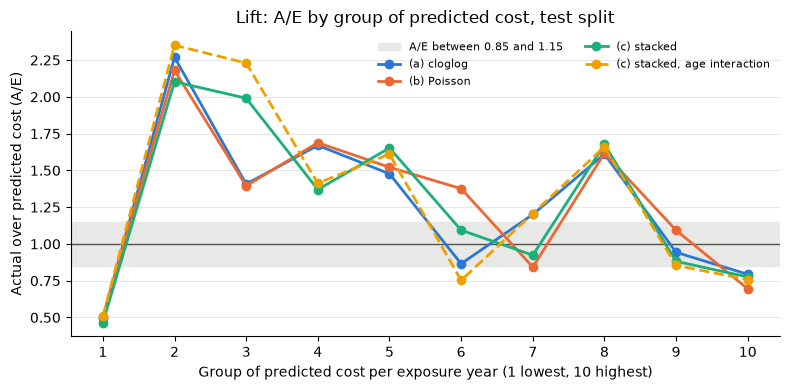

In [45]:
import matplotlib.pyplot as plt

colours = {"a": "#2a78d6", "b": "#eb6834", "c": "#1baf7a", "c_age_interaction": "#eda100"}
styles = {"a": "-", "b": "-", "c": "-", "c_age_interaction": "--"}
labels = {
    "a": "(a) cloglog",
    "b": "(b) Poisson",
    "c": "(c) stacked",
    "c_age_interaction": "(c) stacked, age interaction",
}

lift = comparison.lift_comparison(prepared.test, candidates, "test")
fig, ax = plt.subplots(figsize=(8, 4))
ax.axhspan(0.85, 1.15, color="#e8e8e6", zorder=0, label="A/E between 0.85 and 1.15")
ax.axhline(1.0, color="#52514e", linewidth=1)
for name in candidates:
    ax.plot(
        lift["decile"],
        lift[name],
        color=colours[name],
        linestyle=styles[name],
        marker="o",
        markersize=6,
        linewidth=2,
        label=labels[name],
    )
ax.set_xticks(range(1, 11))
ax.set_xlabel("Group of predicted cost per exposure year (1 lowest, 10 highest)")
ax.set_ylabel("Actual over predicted cost (A/E)")
ax.set_title("Lift: A/E by group of predicted cost, test split")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
ax.grid(axis="y", color="#e8e8e6", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

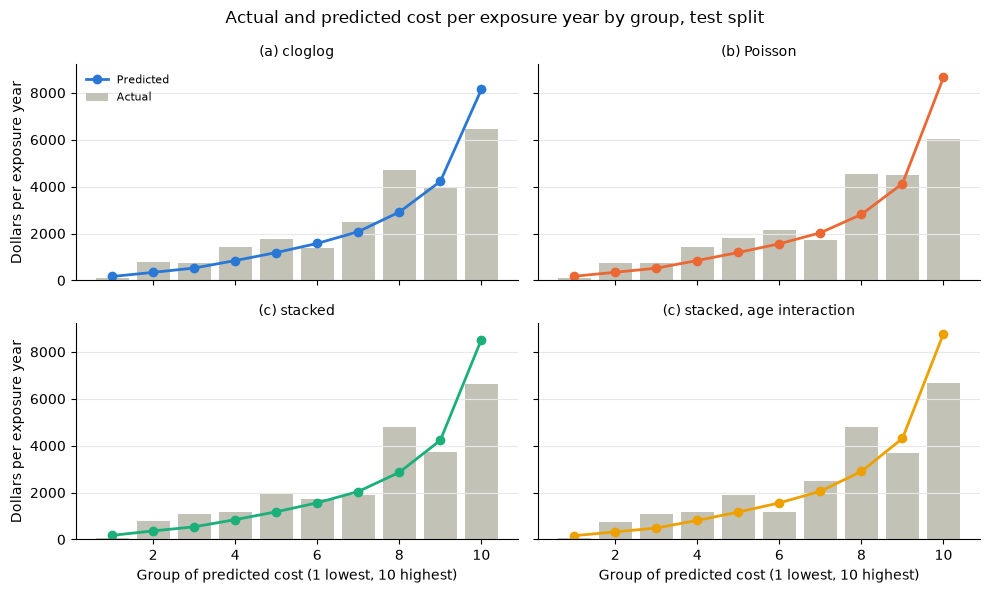

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for ax, name in zip(axes.flat, candidates):
    group = metrics.lift_table(
        prepared.test["cost"], candidates[name].test, prepared.test["exposure"]
    )
    ax.bar(group["group"], group["actual_per_exposure"], color="#c3c2b7", label="Actual")
    ax.plot(
        group["group"],
        group["predicted_per_exposure"],
        color=colours[name],
        marker="o",
        markersize=6,
        linewidth=2,
        label="Predicted",
    )
    ax.set_title(labels[name], fontsize=10)
    ax.grid(axis="y", color="#e8e8e6", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=8, loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("Group of predicted cost (1 lowest, 10 highest)")
for ax in axes[:, 0]:
    ax.set_ylabel("Dollars per exposure year")
fig.suptitle("Actual and predicted cost per exposure year by group, test split")
plt.tight_layout()
plt.show()

Every candidate under-predicts the middle groups, in particular group 8, where actual cost is about 4,700 dollars per
exposure year against a prediction near 2,900. Every candidate over-predicts the top group, where the prediction is
8,100 to 8,700 dollars against an actual of 6,000 to 6,700 (A/E between 0.69 and 0.79). Groups 1 and 2 have a low A/E
but little cost, because their predicted cost is only a few hundred dollars per exposure year. Swings of this size
are within the noise described above, but the top-group over-prediction is shared by every candidate and is worth a
look in the diagnostics.

In [47]:
metrics.double_lift_table(
    prepared.test["cost"],
    candidates["a"].test,
    candidates["c"].test,
    prepared.test["exposure"],
).rename(columns={"a_e_a": "a_e_candidate_a", "a_e_b": "a_e_candidate_c"})

,group,exposure,actual,predicted_a,predicted_b,a_e_candidate_a,a_e_candidate_c
0,1,410.417,"1,291,330.479","963,501.978","1,207,073.448",1.340,1.070
1,2,410.000,"886,714.086","811,403.526","922,209.318",1.093,0.962
2,3,409.750,"893,094.440","883,435.779","958,597.415",1.011,0.932
3,4,410.083,"672,646.003","886,091.687","929,664.713",0.759,0.724
4,5,409.500,"982,786.683","879,255.951","898,124.809",1.118,1.094
5,6,410.167,"942,191.535","883,815.583","879,891.223",1.066,1.071
6,7,410.750,"940,178.450","761,536.110","738,925.252",1.235,1.272
7,8,409.917,"1,501,360.880","914,472.386","862,985.936",1.642,1.740
8,9,410.083,"850,062.927","976,651.732","888,002.088",0.870,0.957
9,10,409.667,"788,617.764","1,065,029.727","872,581.930",0.740,0.904


In [48]:
metrics.double_lift_table(
    prepared.test["cost"],
    candidates["a"].test,
    candidates["b"].test,
    prepared.test["exposure"],
).rename(columns={"a_e_a": "a_e_candidate_a", "a_e_b": "a_e_candidate_b"})

,group,exposure,actual,predicted_a,predicted_b,a_e_candidate_a,a_e_candidate_b
0,1,410.333,"935,064.438","1,411,229.944","1,666,278.232",0.663,0.561
1,2,410.000,"981,073.175","694,186.966","735,015.037",1.413,1.335
2,3,410.250,"652,237.007","691,895.689","715,660.965",0.943,0.911
3,4,409.500,"577,635.638","805,100.940","820,257.333",0.717,0.704
4,5,409.583,"614,589.042","762,535.008","767,124.343",0.806,0.801
5,6,410.917,"1,105,358.544","679,146.872","676,097.882",1.628,1.635
6,7,410.000,"1,112,047.730","903,112.288","889,103.647",1.231,1.251
7,8,409.750,"959,975.815","931,898.916","904,776.810",1.030,1.061
8,9,409.750,"824,356.976","1,020,413.530","969,996.631",0.808,0.850
9,10,410.250,"1,986,644.882","1,125,674.307","996,961.151",1.765,1.993


The double-lift chart plots the two tables above. Person-years are grouped by the ratio of the two predictions, from
the group where candidate (a) predicts lowest relative to the other candidate (left) to the group where it predicts
highest (right). If one candidate is better, its A/E line stays nearer 1 and the other line slopes away from 1 across
the groups. Lines that cross, or that both wander, mean neither candidate is better.

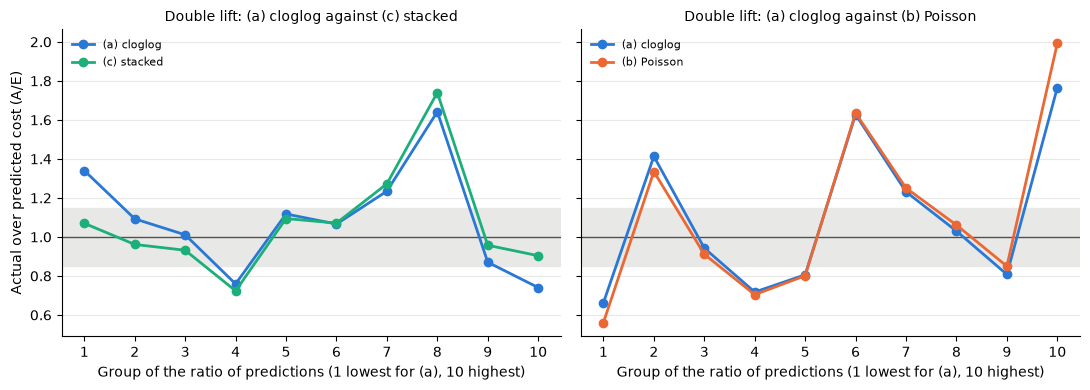

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, other in zip(axes, ("c", "b")):
    table = metrics.double_lift_table(
        prepared.test["cost"],
        candidates["a"].test,
        candidates[other].test,
        prepared.test["exposure"],
    )
    ax.axhspan(0.85, 1.15, color="#e8e8e6", zorder=0)
    ax.axhline(1.0, color="#52514e", linewidth=1)
    ax.plot(
        table["group"],
        table["a_e_a"],
        color=colours["a"],
        marker="o",
        markersize=6,
        linewidth=2,
        label=labels["a"],
    )
    ax.plot(
        table["group"],
        table["a_e_b"],
        color=colours[other],
        marker="o",
        markersize=6,
        linewidth=2,
        label=labels[other],
    )
    ax.set_xticks(range(1, 11))
    ax.set_title(f"Double lift: {labels['a']} against {labels[other]}", fontsize=10)
    ax.set_xlabel("Group of the ratio of predictions (1 lowest for (a), 10 highest)")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    ax.grid(axis="y", color="#e8e8e6", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Actual over predicted cost (A/E)")
plt.tight_layout()
plt.show()

Against candidate (b) the two lines are almost the same in the middle groups, and candidate (a) is nearer 1 in the two
end groups, where the two candidates differ most. Against candidate (c) the lines cross. Candidate (c) is nearer 1 in
groups 1, 2, 5, 9 and 10 and candidate (a) is nearer in groups 3, 4 and 6 to 8, so neither is consistently better.

The lift table is noisy. Each group holds about 415 person-years, and all four candidates show the same pattern, with
A/E above 1 in groups 2 to 5 and 8 and below 1 in the top group. A pattern shared by every structure belongs to this
test split, which is small and has a heavy tail, and not to one structure. In the double-lift tables neither candidate
(a) nor candidate (c) is consistently nearer 1 across the groups, and candidate (a) is nearer 1 than candidate (b) in the two end groups.

### A/E by factor

For every factor level with at least 30 claimants, A/E should be between 0.85 and 1.15. The table counts the levels
outside that band for each candidate, first on the train split, then on the test split, and then on the test split
using capped actual cost and predictions without the load. The capped view removes the noise from a few very large
claims.

In [50]:
pd.concat(
    {
        "train": comparison.ae_flag_counts(prepared.train, candidates, "train"),
        "test": comparison.ae_flag_counts(prepared.test, candidates, "test"),
        "test, capped": comparison.ae_flag_counts(prepared.test, candidates, "test", capped=True),
    }
)

candidate  levels_checked  levels_outside_band  \
train        0                  a              62                    6   
             1                  b              62                    5   
             2                  c              62                    6   
             3  c_age_interaction              62                    7   
test         0                  a              59                   33   
             1                  b              59                   33   
             2                  c              59                   37   
             3  c_age_interaction              59                   34   
test, capped 0                  a              59                   24   
             1                  b              59                   26   
             2                  c              59                   23   
             3  c_age_interaction              59                   25   

                worst_a_e  
train        0      3.644  
             1      4.232  
             2      3.863  
             3      3.723  
test         0      2.543  
             1      2.562  
             2      2.517  
             3      2.760  
test, capped 0      2.708  
             1      2.729  
             2      2.680  
             3      2.939

In [51]:
comparison.ae_flags(
    prepared.test.assign(cost=prepared.test["capped_cost"]),
    candidates["a"].test / (1 + large_claims.PROVISIONAL_LOAD),
    name="a, test, capped",
)

,candidate,factor,level,person_years,exposure,claimants,actual,expected,a_e
0,"a, test, capped",age,00-04,167,150.167,37,"162,850.513","60,127.341",2.708
1,"a, test, capped",age,05-14,459,458.833,80,"231,115.234","147,578.233",1.566
2,"a, test, capped",age,15-17,161,161.000,32,"143,339.062","103,777.440",1.381
3,"a, test, capped",age,18-24,278,275.083,58,"189,141.792","116,401.214",1.625
4,"a, test, capped",age,30-34,247,246.250,77,"323,242.457","233,478.519",1.384
5,"a, test, capped",age,40-44,239,237.250,93,"454,752.381","318,550.171",1.428
6,"a, test, capped",age,45-49,263,262.417,88,"487,463.242","399,402.412",1.220
7,"a, test, capped",age,50-54,237,235.583,103,"301,897.917","540,725.650",0.558
8,"a, test, capped",age,60-64,299,296.250,166,"700,002.562","1,105,640.388",0.633
9,"a, test, capped",age,65-69,320,317.667,196,"1,356,396.721","970,178.883",1.398


On the train split only 5 to 7 of 62 levels are outside the band, as expected for a fitted model. On the test split 33
to 37 of 59 levels are outside it, and 23 to 26 when large claims are capped. The same levels fail for every candidate,
so the structure does not explain it. Cost per person-year is very skewed, so the A/E of a level with a few hundred
claimants has a wide interval, as the overall interval above shows. The flagged levels should not be read as a fault in
one structure. Diagnostics for the chosen structure examine them further. A comparison with less noise would pool the
train and test splits with household-grouped cross-validation, which can be added if small differences matter.

### Recommendation for the gate

**Structure.** Choose candidate (a), the cloglog claimant frequency with a Gamma severity, as the risk model.
- It has the lowest test deviance at all three powers and the highest Gini.
- It is clearly better than the Poisson candidate (b), and cannot be told apart from the stacked candidate (c).
- It has 88 parameters, two fewer than (c).
- Candidate (c) is the alternative if a benefit-type split of the premium is wanted, for example to price an outpatient
  limit in the product layer.
- Candidate (b) is exactly multiplicative but is worse than (a) by more than noise.

**Coverage (`inscov`).** Keep everyone and fit `inscov` as a control that is priced at the private level, as set out in
the level grouping section.

**Factors.** All 18 candidates are used in this comparison. The permitted factors for the final structure are decided
separately.

### Surrogate model (tariff) check

Candidate (a) is not exactly multiplicative, so a rating engine cannot hold it as it is. The check asks how much is lost
when it is replaced by a **surrogate model (tariff)**. This is a multiplicative log-link GLM fitted to the annual cost
that (a) predicts on the train split, and not to actual claims, using the same rating factors. Pricing actuaries call
this tariff extraction, or fitting a rating structure to the technical premium. The surrogate model (tariff) is scored on
the test split with the same yardstick and compared with candidate (b), which is already multiplicative. If the
surrogate model (tariff) of (a) still beats (b), candidate (a) is confirmed. If not, candidate (b) is chosen.

The first table is the departure of the surrogate model (tariff) from candidate (a), as a relative difference per
person-year.

In [52]:
from health_pricing.models import surrogate

tariff_a, surrogate_a = surrogate.surrogate_candidate(prepared, candidates["a"])
print(f"Parameters of the surrogate model (tariff): {tariff_a.parameters}")
surrogate.departure_from_reference(candidates["a"], surrogate_a)

Parameters of the surrogate model (tariff): 43


,split,median_abs_departure,rms_log_departure,p99_abs_departure,max_abs_departure,total_cost_ratio
0,train,0.047,0.087,0.301,0.633,1.000
1,test,0.048,0.090,0.303,0.529,0.998


The typical departure of the surrogate model (tariff) from candidate (a) is 4.7 percent (the median absolute relative
difference). The 99th percentile is 30 percent and the largest is 63 percent on train and 53 percent on test. The total
predicted cost is kept (a ratio of 1.000 on train and 0.998 on test). The surrogate model (tariff) has 43 parameters,
one set of relativities, against 88 for the two parts of candidate (a). The next tables score it on the test split
alongside (a) and (b), and the saved comparison table now includes it.

In [53]:
with_surrogate = {**candidates, "a_surrogate": surrogate_a}
table_with_surrogate = comparison.comparison_table(prepared, with_surrogate)
saved_comparison = comparison.save_comparison(table_with_surrogate)
compared = {name: with_surrogate[name] for name in ("a", "a_surrogate", "b")}
subset = table_with_surrogate[table_with_surrogate["candidate"].isin(list(compared))]
subset

,candidate,split,tweedie_deviance,mean_tweedie_deviance,tweedie_deviance_p1_3,tweedie_deviance_p1_7,gini,a_e,parameters,max_multiplicative_departure,dropped_reason
2,a,train,"2,839,248.949",161.358,"12,093,860.205","838,602.988",0.536,1.012,88.000,0.684,
3,a,test,"808,193.398",194.698,"3,581,078.437","225,668.284",0.433,1.080,88.000,0.432,
4,b,train,"2,858,621.469",162.459,"12,185,510.775","843,134.663",0.532,0.998,88.000,0.000,
5,b,test,"816,054.082",196.592,"3,617,632.707","227,507.386",0.428,1.066,88.000,0.000,
10,a_surrogate,train,"2,862,673.242",162.689,"12,193,634.472","844,639.781",0.532,1.012,43.000,0.000,
11,a_surrogate,test,"814,292.461",196.168,"3,607,960.808","227,151.554",0.426,1.082,43.000,0.000,


In [54]:
comparison.ranking_table(subset)

,candidate,rank_p1_3,rank_p1_5,rank_p1_7
0,a,1,1,1
1,b,3,3,3
2,a_surrogate,2,2,2


In [55]:
comparison.deviance_difference_interval(prepared.test, compared, reference="b")

,candidate,versus,deviance_difference,lower_95,upper_95,share_better_than_reference
0,a,b,"-7,860.683","-15,606.586","-1,920.839",1.000
1,a_surrogate,b,"-1,761.621","-5,751.643","1,756.266",0.833


On the test split the surrogate model (tariff) has a lower deviance than candidate (b) at all three powers (814,292
against 816,054 at p = 1.5, and the order is the same at 1.3 and 1.7). Its Gini is slightly lower (0.426 against 0.428).
The deviance difference is -1,762 points, with an interval of -5,752 to 1,756, and the surrogate model (tariff) is better
than (b) in 83 percent of resamples, so the advantage is small and within sampling noise. The surrogate model (tariff) is
worse than candidate (a) by 6,099 points (0.75 percent), which is the price of putting (a) into a multiplicative form.

In [56]:
for pair in (("a_surrogate", "b"), ("a_surrogate", "a")):
    print(f"Double lift: {pair[0]} against {pair[1]}")
    display(
        metrics.double_lift_table(
            prepared.test["cost"],
            compared[pair[0]].test,
            compared[pair[1]].test,
            prepared.test["exposure"],
        ).rename(columns={"a_e_a": f"a_e_{pair[0]}", "a_e_b": f"a_e_{pair[1]}"})
    )

Double lift: a_surrogate against b


,group,exposure,actual,predicted_a,predicted_b,a_e_a_surrogate,a_e_b
0,1,409.833,"2,818,166.516","2,767,703.649","2,986,421.844",1.018,0.944
1,2,410.500,"1,317,781.429","1,381,643.642","1,418,042.838",0.954,0.929
2,3,410.167,"1,047,062.180","1,006,563.342","1,013,051.833",1.040,1.034
3,4,409.417,"1,121,389.528","835,082.345","829,028.931",1.343,1.353
4,5,409.917,"922,578.119","717,041.995","704,488.069",1.287,1.310
5,6,410.500,"543,356.239","662,483.107","643,497.096",0.820,0.844
6,7,409.917,"752,705.324","546,368.607","525,144.330",1.378,1.433
7,8,410.083,"482,975.709","465,514.265","442,118.443",1.038,1.092
8,9,409.583,"538,700.483","379,678.636","355,661.579",1.419,1.515
9,10,410.417,"204,267.720","245,108.263","223,817.068",0.833,0.913


Double lift: a_surrogate against a


,group,exposure,actual,predicted_a,predicted_b,a_e_a_surrogate,a_e_a
0,1,410.000,"2,092,119.811","1,075,590.996","1,222,648.695",1.945,1.711
1,2,409.583,"1,548,040.540","1,142,477.198","1,199,022.892",1.355,1.291
2,3,410.417,"1,486,958.196","1,405,074.962","1,440,102.313",1.058,1.033
3,4,410.333,"966,483.771","1,171,145.088","1,180,979.748",0.825,0.818
4,5,410.083,"769,770.122","910,483.506","905,357.676",0.845,0.850
5,6,409.333,"796,067.153","888,426.749","867,123.966",0.896,0.918
6,7,410.000,"651,758.529","776,634.756","741,587.250",0.839,0.879
7,8,410.667,"697,848.000","615,207.084","572,501.691",1.134,1.219
8,9,410.167,"493,532.613","600,942.366","540,965.820",0.821,0.912
9,10,409.750,"246,404.513","421,205.146","354,904.407",0.585,0.694


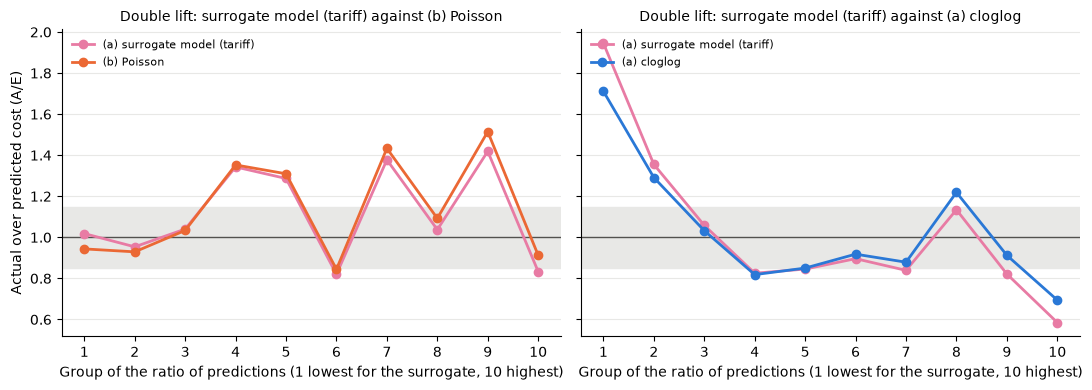

In [57]:
colours["a_surrogate"] = "#e87ba4"
labels["a_surrogate"] = "(a) surrogate model (tariff)"
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, other in zip(axes, ("b", "a")):
    table = metrics.double_lift_table(
        prepared.test["cost"],
        compared["a_surrogate"].test,
        compared[other].test,
        prepared.test["exposure"],
    )
    ax.axhspan(0.85, 1.15, color="#e8e8e6", zorder=0)
    ax.axhline(1.0, color="#52514e", linewidth=1)
    for column, name in (("a_e_a", "a_surrogate"), ("a_e_b", other)):
        ax.plot(
            table["group"],
            table[column],
            color=colours[name],
            marker="o",
            markersize=6,
            linewidth=2,
            label=labels[name],
        )
    ax.set_xticks(range(1, 11))
    ax.set_title(f"Double lift: surrogate model (tariff) against {labels[other]}", fontsize=10)
    ax.set_xlabel("Group of the ratio of predictions (1 lowest for the surrogate, 10 highest)")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    ax.grid(axis="y", color="#e8e8e6", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Actual over predicted cost (A/E)")
plt.tight_layout()
plt.show()

Against candidate (b) the surrogate model (tariff) is nearer 1 in 7 of the 10 double-lift groups. Against candidate (a),
candidate (a) is nearer 1 in 8 of 10 groups, as expected for an approximation of it.

**Result.** The surrogate model (tariff) of candidate (a) has a lower Tweedie deviance than candidate (b) on the test
split at p = 1.5, 1.3 and 1.7, and is nearer 1 in most double-lift groups, so candidate (a) is confirmed. The margin is
small. The Gini is marginally lower than (b), and the deviance gap is within sampling noise. The check shows that putting
(a) into a multiplicative form does not lose its advantage over (b), but not that it is clearly better.

**Candidate (a) or (c).** Candidates (a) and (c) are statistically indistinguishable, so candidate (a) is chosen on
simplicity. Candidate (c) is the option if the product layer later needs separate inpatient and outpatient pricing, for
example an outpatient limit.

**Test A/E.** The overall test A/E of 1.08 and the level-by-level failures are consistent with a small test split, a heavy
tail and the provisional large-claim load. They are noted and are not tuned away.

## Permitted rating factors (decision gate 7, part 2)

The model structure is candidate (a). This section decides which factors the final rating structure may use. The
comparison above used all 18 candidates. Two options for the permitted set are compared, and each rating factor in them
is then tested.

- **Option 1.** Self-rated health (`rthlth`, `mnhlth`), exercise (`PHYEXE53`) and insurance coverage (`inscov`) are
  analysis-only. Age, region, smoking and the 11 condition flags are rating factors.
- **Option 2.** As option 1, and the condition flags are analysis-only too. UK individual private medical insurance usually
  handles pre-existing conditions through exclusions (a moratorium or full medical underwriting) and not through premium
  loadings, so the condition flags would not price the policy. Age, region and smoking are the rating factors.
- **All factors** is the model from the comparison, shown for reference.

An analysis-only factor is fitted as a control, so it adjusts the relativities of the other factors, and is priced at its
reference level when predicting. This is the treatment agreed for `inscov`. Pricing a control at its reference level
leaves the base rate too low for the book as a whole, because the reference level is not the average. Each option is
therefore **rebalanced**, which means its predictions are scaled so that predicted cost on the train split equals actual
cost on the train split. The test split is not used for this.

In [58]:
from health_pricing.models import factors

results = factors.option_results(prepared)
tests = {}
for option in ("option_1", "option_2"):
    table = factors.drop_one_tests(
        prepared.train, factors.OPTIONS[option], factors.controls_for(option)
    )
    tests[option] = table.assign(option=option)
saved_tests = factors.save_table(pd.concat(tests.values(), ignore_index=True), "factor_tests.csv")
{option: results[option].rebalance_factor for option in results}

{'all_factors': 1.0120793448957084,
 'option_1': 1.1557167289110744,
 'option_2': 1.9410873847520103}

### Testing each rating factor

Each factor is dropped in turn from the structure and both parts (frequency and severity) are fitted again. The
likelihood-ratio statistic is the fall in deviance, with the severity part divided by the dispersion of the fuller model,
summed over the two parts and compared with a chi-squared distribution. The change in AIC is the statistic minus twice the
extra degrees of freedom, so a positive value means the factor improves the fit once its cost in parameters is counted.
AIC is comparable here because the two models share the same response and the same likelihood. Each factor is tested given
the others in its option, so factors that carry related information, such as the heart conditions, can look weaker than
they would alone.

In [59]:
tests["option_1"]

,factor,levels_dropped,lr_statistic,p_value,aic_change_if_dropped,keep_by_aic,option
0,age,30,446.910,0.000,386.910,True,option_1
1,region,6,67.898,0.000,55.898,True,option_1
2,OFTSMK53,4,58.180,0.000,50.180,True,option_1
3,HIBPDX,2,7.731,0.021,3.731,True,option_1
4,CHDDX,2,9.320,0.009,5.320,True,option_1
5,ANGIDX,2,4.682,0.096,0.682,True,option_1
6,MIDX,2,0.762,0.683,-3.238,False,option_1
7,OHRTDX,2,96.166,0.000,92.166,True,option_1
8,STRKDX,2,0.927,0.629,-3.073,False,option_1
9,CHOLDX,2,40.844,0.000,36.844,True,option_1


In [60]:
tests["option_2"]

,factor,levels_dropped,lr_statistic,p_value,aic_change_if_dropped,keep_by_aic,option
0,age,30,446.910,0.000,386.910,True,option_2
1,region,6,67.898,0.000,55.898,True,option_2
2,OFTSMK53,4,58.180,0.000,50.180,True,option_2


In option 1 most rating factors are supported by both the test and AIC. Age, region, smoking, and the conditions cancer,
arthritis, other heart disease, high cholesterol and asthma have p-values below 0.001. High blood pressure (p = 0.021) and
coronary heart disease (p = 0.010) are supported more weakly, and AIC improves by 3.7 and 5.3 when they are kept. Angina
is borderline (p = 0.096, and AIC improves by 0.7). Heart attack (`MIDX`), stroke (`STRKDX`) and diabetes (`DIABDX_M18`)
are not supported. Their p-values are 0.68, 0.63 and 0.32, and AIC is better without them by 3.2, 3.1 and 1.7. The heart
related flags carry overlapping information, so each looks weaker given the others. In option 2 all three rating factors
are strongly supported.

In [61]:
selected = factors.select_by_aic(tests["option_1"])
results["option_1_selected"] = factors.scored_option(
    prepared, "option_1_selected", selected, factors.controls_for("option_1")
)
option_scores = factors.option_scores(prepared, results)
saved_options = factors.save_table(option_scores, "permitted_factor_options.csv")
print(f"Rating factors kept in option_1_selected: {len(selected)} of 14")
option_scores

Rating factors kept in option_1_selected: 11 of 14


,candidate,split,rating_factors,rebalance_factor,tweedie_deviance,mean_tweedie_deviance,tweedie_deviance_p1_3,tweedie_deviance_p1_7,gini,a_e,parameters
0,all_factors,train,18,1.012,"2,839,245.010",161.357,"12,093,494.866","838,628.930",0.536,1.000,88
1,all_factors,test,18,1.012,"807,323.694",194.489,"3,578,021.935","225,428.953",0.433,1.067,88
2,option_1,train,14,1.156,"3,019,691.267",171.612,"12,824,330.524","885,356.061",0.498,1.000,88
3,option_1,test,14,1.156,"829,537.165",199.840,"3,664,694.074","231,247.806",0.393,1.080,88
4,option_2,train,3,1.941,"3,329,310.183",189.208,"14,293,912.808","951,414.184",0.373,1.000,88
5,option_2,test,3,1.941,"854,746.002",205.913,"3,786,919.943","236,395.976",0.329,1.080,88
6,option_1_selected,train,11,1.156,"3,019,625.480",171.609,"12,821,578.995","885,416.532",0.497,1.000,82
7,option_1_selected,test,11,1.156,"829,405.297",199.809,"3,663,760.567","231,237.453",0.394,1.080,82


In [62]:
option_candidates = {name: result.candidate for name, result in results.items()}
comparison.deviance_difference_interval(prepared.test, option_candidates, reference="all_factors")

,candidate,versus,deviance_difference,lower_95,upper_95,share_better_than_reference
0,option_1,all_factors,"22,213.471","-6,794.886","50,328.965",0.074
1,option_2,all_factors,"47,422.309","-3,001.061","90,462.519",0.030
2,option_1_selected,all_factors,"22,081.603","-7,322.169","50,330.910",0.073


In [63]:
comparison.overall_ae_interval(prepared.test, option_candidates)

,candidate,a_e,lower_95,upper_95
0,all_factors,1.067,0.881,1.290
1,option_1,1.080,0.895,1.306
2,option_2,1.080,0.894,1.305
3,option_1_selected,1.080,0.895,1.306


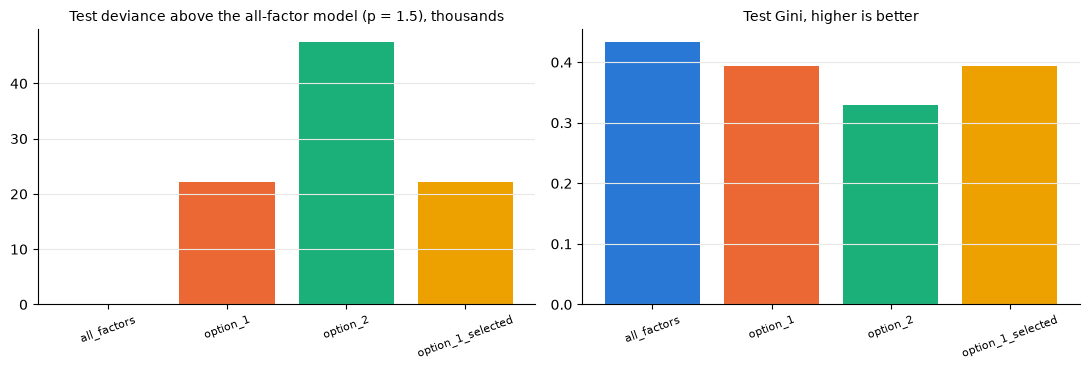

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
test_scores = option_scores[option_scores["split"] == "test"]
names = list(test_scores["candidate"])
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
extra = (test_scores["tweedie_deviance"] - test_scores["tweedie_deviance"].iloc[0]) / 1000
axes[0].bar(names, extra, color=palette[: len(names)])
axes[0].set_title("Test deviance above the all-factor model (p = 1.5), thousands", fontsize=10)
axes[0].tick_params(axis="x", labelrotation=20, labelsize=8)
axes[1].bar(names, test_scores["gini"], color=palette[: len(names)])
axes[1].set_title("Test Gini, higher is better", fontsize=10)
axes[1].tick_params(axis="x", labelrotation=20, labelsize=8)
for ax in axes:
    ax.grid(axis="y", color="#e8e8e6", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

Option 1 has a test deviance 22,213 higher than the all-factor model (2.8 percent) and a lower Gini (0.393 against
0.433). Option 2 is 47,422 higher (5.9 percent) with a Gini of 0.329. Both are better than the overall-mean baseline
(928,364). The intervals for the differences include zero (-6,795 to 50,329, and -3,001 to 90,463), so on this small
split neither can be shown to be worse, but the point estimates all go the same way and the loss of Gini is larger.
Option 1 with the three unsupported flags removed (`option_1_selected`, 11 rating factors) scores the same as option 1
(829,405 against 829,538), so the three flags can be dropped at no cost.

The all-factor row here is rebalanced, so its deviance (807,324) differs slightly from candidate (a) in the comparison
(808,193). The rebalancing factors are 1.012 for all factors, 1.156 for option 1 and 1.941 for option 2. They show how
much the analysis-only factors move the average. Pricing them at their reference level means the base rate has to be raised by
16 percent (option 1) and 94 percent (option 2) to cover the book, which is what rebalancing does.

### Exercise: an insight and not a rating factor

Exercise (`PHYEXE53`) is analysis-only. This section shows its relationship with claims cost. The first table compares adults
by exercise level before any adjustment. The second table gives the relativity of not exercising against exercising once
age, region, health and the other factors are held fixed, from the model with all factors, with a 95 percent interval for
each part. A relativity of 1 means no effect.

In [65]:
exercise = factors.exercise_table(prepared.train)
exercise

,PHYEXE53,person_years,exposure,claimants,mean_age,claimant_rate,capped_cost_per_exposure_year
0,1,7125,"7,119.833",3213,49.018,0.451,"2,050.626"
1,0,6898,"6,896.500",3285,50.181,0.476,"2,688.677"
2,unknown,186,94.750,73,68.495,0.392,"11,783.741"


In [66]:
model_all = glm.fit_two_part(prepared.train, "cloglog", name="a")
effect = factors.adjusted_effect(model_all, prepared.train, "PHYEXE53")
effect

,level,frequency_relativity,frequency_lower_95,frequency_upper_95,severity_relativity,severity_lower_95,severity_upper_95,claimants
0,0,0.971,0.920,1.024,1.072,0.955,1.203,3287


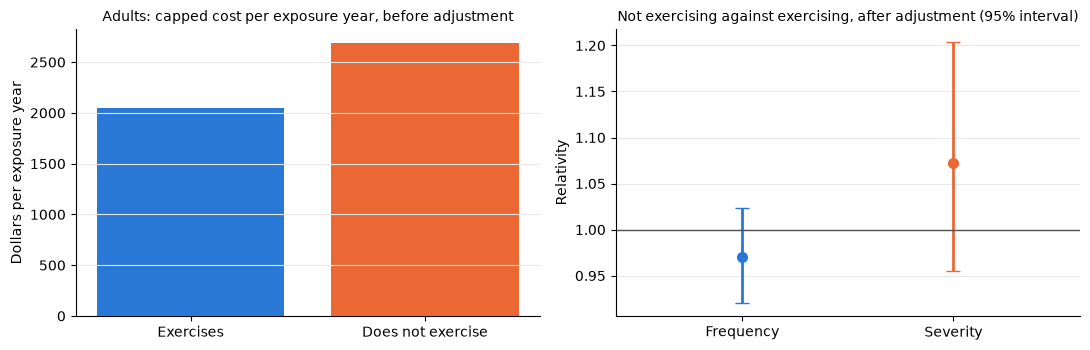

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
shown = exercise[exercise["PHYEXE53"] != "unknown"]
axes[0].bar(
    ["Exercises" if level == "1" else "Does not exercise" for level in shown["PHYEXE53"]],
    shown["capped_cost_per_exposure_year"],
    color=["#2a78d6", "#eb6834"],
)
axes[0].set_title("Adults: capped cost per exposure year, before adjustment", fontsize=10)
axes[0].set_ylabel("Dollars per exposure year")
row = effect[effect["level"] == "0"].iloc[0]
for position, part in enumerate(("frequency", "severity")):
    centre = row[f"{part}_relativity"]
    axes[1].errorbar(
        position,
        centre,
        yerr=[[centre - row[f"{part}_lower_95"]], [row[f"{part}_upper_95"] - centre]],
        fmt="o",
        markersize=7,
        capsize=5,
        linewidth=2,
        color=["#2a78d6", "#eb6834"][position],
    )
axes[1].axhline(1.0, color="#52514e", linewidth=1)
axes[1].set_xticks([0, 1], ["Frequency", "Severity"])
axes[1].set_xlim(-0.6, 1.6)
axes[1].set_title("Not exercising against exercising, after adjustment (95% interval)", fontsize=10)
axes[1].set_ylabel("Relativity")
for ax in axes:
    ax.grid(axis="y", color="#e8e8e6", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

Adults who do not exercise cost 31 percent more per exposure year before adjustment (2,689 dollars of capped cost against
2,051), and their claimant rate is 47.6 percent against 45.1 percent. Once the other factors are held fixed the effect is
no longer clear. The frequency relativity is 0.97 (interval 0.92 to 1.02) and the severity relativity is 1.07 (0.96 to
1.20), and both intervals include 1. The raw difference reflects who does not exercise and not exercise itself. Their mean
age is 50 against 49. Adults who were never asked (`unknown`, 186 person-years) cost 11,784 dollars per exposure year,
which is the leaver effect described in the leakage check and not an effect of exercise. Exercise gives no rating signal
beyond the other factors, which supports keeping it analysis-only.

### Decision for the gate

The table summarises the options on the test split. All options are rebalanced on train.

| Option | Rating factors | Test deviance (p = 1.5) | Test Gini |
|---|---|---|---|
| All factors (reference only) | 18 | 807,324 | 0.433 |
| Option 1 | 14 | 829,537 | 0.393 |
| Option 1, selected by AIC | 11 | 829,405 | 0.394 |
| Option 2 | 3 | 854,746 | 0.329 |

**Recommendation.** Option 1 with the three factors that the tests do not support (heart attack, stroke and diabetes)
removed. That gives 11 rating factors, which are age, region, smoking and eight condition flags.
- It keeps most of the ranking power of the all-factor model (Gini 0.394 against 0.433).
- The condition flags simulate full medical underwriting, as planned, and the three removed flags cost nothing on the test.
- Angina is borderline and is kept on AIC.
- Option 2 is closer to UK practice of handling conditions through exclusions, but gives up much of the ranking power
  (Gini 0.329). It is shown as the sensitivity that prices the cost of that approach.

**For the user to decide.** The permitted set (option 1, option 2 or another), and whether to drop the three unsupported
flags.